In [ ]:
import numpy as np
def get_neighbors(cell: tuple[int, int], map: np.ndarray) -> list(tuple[int, int]):
    """ Gets a numpy array with all the adjacent cell indices """
    cell_idx = np.array(cell)
    neighbors = cell_idx[None,:]+np.array([[-1,0],[1,0],[0,-1],[0,1]])
    not_edge_of_map = (neighbors[:,0]>=0) & (neighbors[:,0]<map.shape[0]) & (neighbors[:,1]>=0) & (neighbors[:,1]<map.shape[1])
    neighbors = [tuple(n) for n in neighbors[not_edge_of_map]]
    return neighbors

[[6. 5. 4. 3. 3. 4. 5. 6. 7. 8.]
 [5. 4. 3. 2. 2. 3. 4. 5. 6. 7.]
 [4. 3. 2. 1. 1. 2. 3. 4. 5. 6.]
 [3. 2. 1. 0. 0. 1. 2. 3. 4. 5.]
 [3. 2. 1. 0. 1. 2. 3. 4. 4. 5.]
 [4. 3. 2. 1. 2. 3. 4. 4. 3. 4.]
 [5. 4. 3. 2. 3. 4. 4. 3. 2. 3.]
 [6. 5. 4. 3. 4. 4. 3. 2. 1. 2.]
 [7. 6. 5. 4. 4. 3. 2. 1. 0. 1.]
 [8. 7. 6. 5. 5. 4. 3. 2. 1. 2.]]


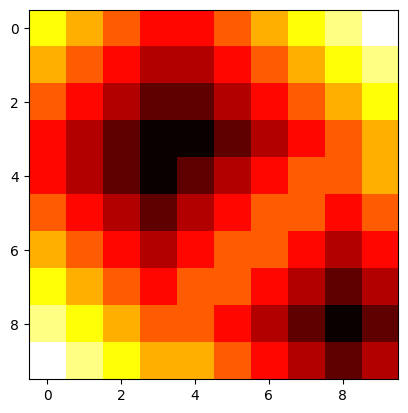

In [ ]:
def lower_cells(map: np.ndarray, cells: list[tuple[int, int]], distance):
    """
    Updates cells with an decreasing distance from an obstacle.
    Used to insert an obstacle and update its neighbors.
    """
    # Initialize the original cells to the specified distance
    for cell in cells:
      map[cell[0], cell[1]] = distance

    open_list = cells.copy()
    closed_list = []
    while len(open_list) > 0:
      cell = open_list.pop(0)
      neighbors = get_neighbors(cell, map)
      neighbor_dist = map[cell[0],cell[1]] + 1
      for neighbor in neighbors:
        if neighbor in (closed_list+open_list):
          continue
        if map[neighbor[0], neighbor[1]] > neighbor_dist:
          map[neighbor[0], neighbor[1]] = neighbor_dist
          open_list.append(neighbor)
      closed_list.append(cell)

def add_obstacles(map: np.ndarray, cells: list[tuple[int, int]]) -> list[tuple[int,int]]:
    lower_cells(map, cells, 0)
    return cells

# Visualize the map as a heatmap
import matplotlib.pyplot as plt
map = np.ones((10,10)) * np.inf
# Add an obstacle in the middle of the map
lower_cells(map, [(4,3),(3,3),(3,4),(8,8)], 0)

print(map)
# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.show()

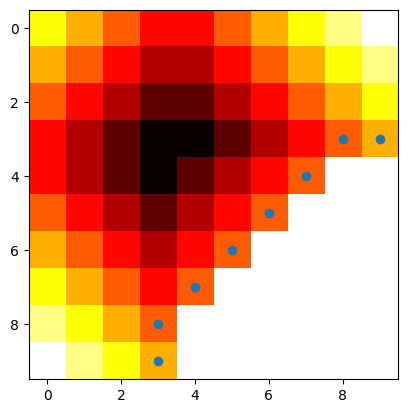

In [ ]:
def raise_cells(map: np.ndarray, cells: list[tuple[int, int]]) -> list[tuple[int,int]]:
    """
    Updates cells with an increasing distance from an obstacle.
    Used to remove an obstacle and update its neighbors.

    When the wavefront hits a cell that can't be updated then we keep track of it.
    Then we return a list of all cells that are not updated so they can be called
    using raise.
    """
    #add all cells to deque
    open_list = cells.copy()
    closed_list = []

    boundary_cells = []
    while len(open_list) > 0:
        cell = open_list.pop(0)
        old_dist = map[cell[0], cell[1]]
        map[cell[0], cell[1]] = np.inf
        closed_list += [cell]
        for neighbor in get_neighbors(cell, map):
          if neighbor in open_list+boundary_cells+closed_list:
            continue
          if map[neighbor[0], neighbor[1]] <= old_dist:
            boundary_cells += [neighbor]
          else:
            open_list.append(neighbor)
    return boundary_cells

map = np.ones((10,10)) * np.inf
add_obstacles(map, [(4,3),(3,3),(3,4),(8,8)])
boundary_cells = raise_cells(map, [(8,8)])

# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.scatter(*zip(*boundary_cells))
plt.show()

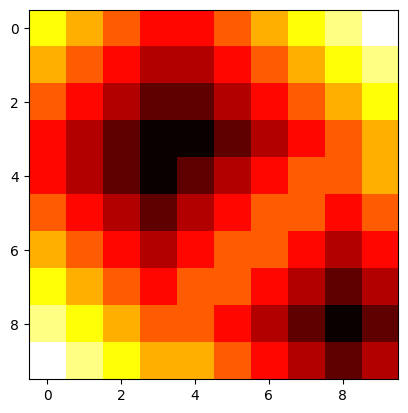

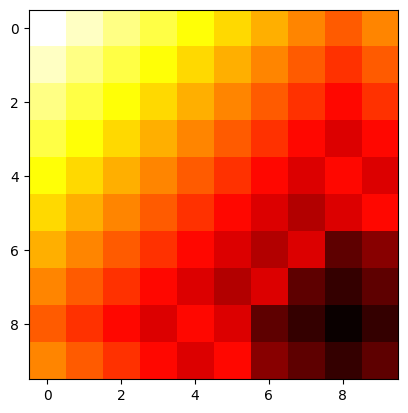

In [ ]:
def delete_obstacles(map: np.ndarray, cells: list[tuple[int, int]]) -> list[tuple[int,int]]:
    boundary_cells = raise_cells(map, cells)
    for cell in boundary_cells:
      cell_dist = map[cell[0], cell[1]]
      lower_cells(map, get_neighbors(cell, map), cell_dist+1)

map = np.ones((10,10)) * np.inf
add_obstacles(map, [(4,3),(3,3),(3,4)])
add_obstacles(map, [(8,8)])

# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.show()

delete_obstacles(map, [(3,3),(4,3),(3,4)])
# Visualize the map again
plt.imshow(map, cmap='hot', interpolation='nearest')
plt.show()

In [ ]:
def distance_ray(x, theta, map, max_range=4, step=0.1):
    n, m = map.shape
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    for d in np.linspace(0,max_range, int(max_range // step)):
      point = x[:2] + d * ray
      cell = (round(point[0]), round(point[1]))
      if cell[0] < 0 or cell[0] >= n or cell[1] < 0 or cell[1] >= m:
        return d - step
      if map[cell[0], cell[1]] == 0:
        return d
    return max_range

def scan_map(x, map, max_range = 4.0, theta_res=0.2):
    theta_range = np.arange(-np.pi,np.pi,theta_res)
    dists = []
    for theta in theta_range:
      dist = distance_ray(x, theta, map, max_range=max_range)
      dists.append(dist)
    dists = np.array(dists)
    return dists, theta_range

def ray_prob(point: np.ndarray, map:np.ndarray, std = 0.5):
    i, j = round(point[0]), round(point[1])
    n, m = map.shape
    out_of_bounds_dist = 0
    # Handle rays that go out of bounds
    if i < 0:
      i = 0
      out_of_bounds_dist += abs(i-point[0])
    elif i >= n:
      i = n-1
      out_of_bounds_dist += abs(i-point[0])
    if j < 0:
      j = 0
      out_of_bounds_dist += abs(j-point[1])
    elif j >= m:
      j = m-1
      out_of_bounds_dist += abs(j-point[1])

    dist = map[i, j] + out_of_bounds_dist
    return np.exp(-dist**2/(2*std**2))/np.sqrt(2*np.pi*std**2)

def likelihood_field_range_finder(z_dists, z_thetas, x, map, z_max = 4.0, std=0.5):
  q = 1
  eps = 0.02
  n, m = map.shape
  for z, theta in zip(z_dists, z_thetas):
    if z > z_max - eps:
      continue
    ray_theta = x[2] + theta
    ray = np.array([np.cos(ray_theta), np.sin(ray_theta)])
    point = x[:2] + z * ray
    q *= ray_prob(point, map, std=std)
  return q



## Map Generation & Plotting

This next code block contains two functions.

`create_medium_map` assists in creating a 50x50 map for the next stage of our demonstration.

`plot_map_and_scans` will assist in visualizing the map and lidar scans.

I typically leave this code block hidden as it doesn't add to the demonstration but you are free to examine or edit this as you experiment with the code.

In [ ]:
# @title
def create_medium_map():
  # Create a 100x100 map initialized with infinity
  map = np.ones((50, 50)) * np.inf

  # Add walls on the perimeter by setting distance to 0 for the border cells
  border_cells = []
  for i in range(50):
      border_cells.append((0, i))
      border_cells.append((49, i))
      border_cells.append((i, 0))
      border_cells.append((i, 49))

  # Add 5x8 obstacles inside
  obstacle_size_x = 5
  obstacle_size_y = 5
  num_obstacles = 10

  # Define positions for obstacles (adjust as needed)
  obstacle_positions = [
      (5, 5), (12, 15), (40, 50), (30, 35), (40, 10),
      (15, 40), (25, 20), (35, 30), (40, 40), (40, 5)
  ]
  obstacle_cells = []

  for start_x, start_y in obstacle_positions:
      for i in range(obstacle_size_x):
          for j in range(obstacle_size_y):
              cell_x = start_x + i
              cell_y = start_y + j
              # Ensure the obstacle stays within the map boundaries
              if 0 < cell_x < 49 and 0 < cell_y < 49:
                  obstacle_cells.append((cell_x, cell_y))

  add_obstacles(map, border_cells+obstacle_cells)
  return map

def plot_map_and_scans(z_dists, z_thetas, x, map):
    """
    Plots the map, robot position, and scan endpoints.
    """
    plt.imshow(map, cmap='hot', interpolation='nearest')
    plt.plot(x[1], x[0], 'bo', markersize=10, label='Robot')  # Robot position (note the transpose for plotting)

    scan_endpoints = []
    for dist, theta in zip(z_dists, z_thetas):
        # Calculate the endpoint of the scan
        endpoint_x = x[0] + dist * np.cos(x[2] + theta)
        endpoint_y = x[1] + dist * np.sin(x[2] + theta)
        scan_endpoints.append((endpoint_y, endpoint_x))  # Note the transpose for plotting

    if scan_endpoints:
        scan_endpoints = np.array(scan_endpoints)
        plt.scatter(scan_endpoints[:, 0], scan_endpoints[:, 1], color='g', s=5, label='Scan Endpoints')

    plt.title('Map with Robot and Scan')
    plt.xlabel('Y-coordinate')
    plt.ylabel('X-coordinate')
    plt.legend()
    plt.show()